In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import ridge_regression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt


%load_ext autoreload
%autoreload 2


# 01 — Synthetic Data Validation & Variance Reduction


### DATASET LOADING:
We load the **California Housing** dataset (1990 US census) as pandas structures (`as_frame=True`), consisting of **20,640 block-group samples** and **8 numerical features** (`X`) covering socioeconomic indicators (`MedInc`), housing characteristics (`HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`), and geographic coordinates (`Latitude`, `Longitude`). 

The target variable (`y`, `MedHouseVal`) represents the median house value in hundreds of thousands of dollars ($100k) and is capped at `5.00001` ($500,000). While not transferable to different real-world housing markets due to domain shift, this dataset provides a clean non-linear benchmark—especially across spatial coordinates—to validate our from-scratch Random Forest implementation.


In [2]:
data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
print(X.shape)
print(y.head())
X.head()

(20640, 8)
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### MISSING VALUES & OUTLIERS CHECK

A quick inspection (`X.isna().sum()` and `X.describe()`) confirms there are **no missing values** across any of the 20,640 rows, so our custom tree implementation won't need `NaN`-handling logic.

The feature distributions do contain heavy right-tail outliers—most notably `AveRooms` (max `141.9`), `AveOccup` (max `1243.3`), and `Population` (max `35,682`)—caused by block groups with very few households alongside large institutions or hotels, plus an upper cap on `HouseAge` at `52.0`. We intentionally keep all rows untouched: tree-based models partition data via rank/threshold splits and are naturally insensitive to extreme feature values, whereas dropping them would break comparability with standard benchmarks. Conversely, both median and linear regression struggle with extreme values.



In [3]:
# Verify zero missing values and inspect min/max ranges for extreme outliers or caps
print("Missing values per column:\n", X.isna().sum())
display(X.describe().loc[["min", "50%", "max"]])


Missing values per column:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
min,0.4999,1.0,0.846154,0.333333,3.0,0.692308,32.54,-124.35
50%,3.5348,29.0,5.229129,1.048780,1166.0,2.818116,34.26,-118.49
max,15.0001,52.0,141.909091,34.066667,35682.0,1243.333333,41.95,-114.31


### TRAIN/TEST SPLIT & BASELINE BENCHMARKS:

We split the data into 80% training (16,512 samples) and 20% test (4,128 samples) sets, fixing `random_state=42` to ensure reproducibility and a fair, identical test set for comparing `scikit-learn` against our custom implementation.

Three models of increasing complexity are evaluated using Mean Absolute Error (MAE) (expressed in $100k units):
- Median Baseline (`DummyRegressor`): Always predicts the training median, establishing the minimum performance floor.
- Multiple Linear Regression (`StandardScaler` + `LinearRegression`): Standardizes all features to zero mean and unit variance before fitting a global linear hyperplane.
- Random Forest (`RandomForestRegressor`): Fits an ensemble of 10 decision trees (`n_estimators=10`) capable of capturing non-linear interactions and spatial thresholds. Its test MAE serves as the target benchmark for our from-scratch model.

The models were evaluated using **Mean Absolute Error (MAE)** (in $100k units) as our primary metric because:
1. Interpretability: It expresses the average error directly in the target's unit (e.g., `0.33` = $33,000).
2. Baseline consistency: The sample median (`DummyRegressor`) is the theoretical minimizer of MAE.
3. Robustness to the $500k cap: Unlike MSE/RMSE, MAE scales linearly and is not disproportionately skewed by the ~5% of districts artificially capped at `5.00001`.




In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

N = 5000
X_tr_sub = X_tr[:N]
y_tr_sub = y_tr[:N]
print(
    f"Train subsample: {len(X_tr_sub)}\n"
    f"Test set: {len(X_te)}"
)

modelli = {
    "median (baseline)": DummyRegressor(strategy="median"),
    "LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
    "RandomForest sklearn": RandomForestRegressor(
        n_estimators=10,
        max_depth=8,
        max_features=1.0,
        random_state=0,
        n_jobs=-1,
    ),
}

rows = []
for nome, m in modelli.items():
    m.fit(X_tr_sub, y_tr_sub)
    mae = mean_absolute_error(y_te, m.predict(X_te))
    rows.append({
        "Model": nome,
        "MAE": mae,
    })

df_sub = pd.DataFrame(rows)
display(
    df_sub.style
    .hide(axis="index")
    .format({"MAE": "{:.3f}"})
    .highlight_min(subset=["MAE"], color="#2e7d32")
)


Train subsample: 5000
Test set: 4128


Model,MAE
median (baseline),0.875
LinearRegression,0.532
RandomForest sklearn,0.413


### ACTUAL vs PREDICTED PLOTS

A single MAE score hides where each model is failing, so here we plot the real test prices (`y_te`) against the predicted values (`y_pred`), using the dashed red diagonal ($y = x$) as a reference for perfect predictions.

Three distinct behaviors stand out:
- The median baseline collapses onto a flat horizontal line since it outputs the exact same constant regardless of the house features.
- Linear regression catches the general upward trend, but because a global hyperplane cannot bend at boundaries, it spills into unbounded predictions—dipping into negative prices on the low end and shooting well past `5.0` on the high end.
- `RandomForestRegressor` tightens much more closely around the diagonal and naturally stops at the dataset's `5.00001` ceiling.



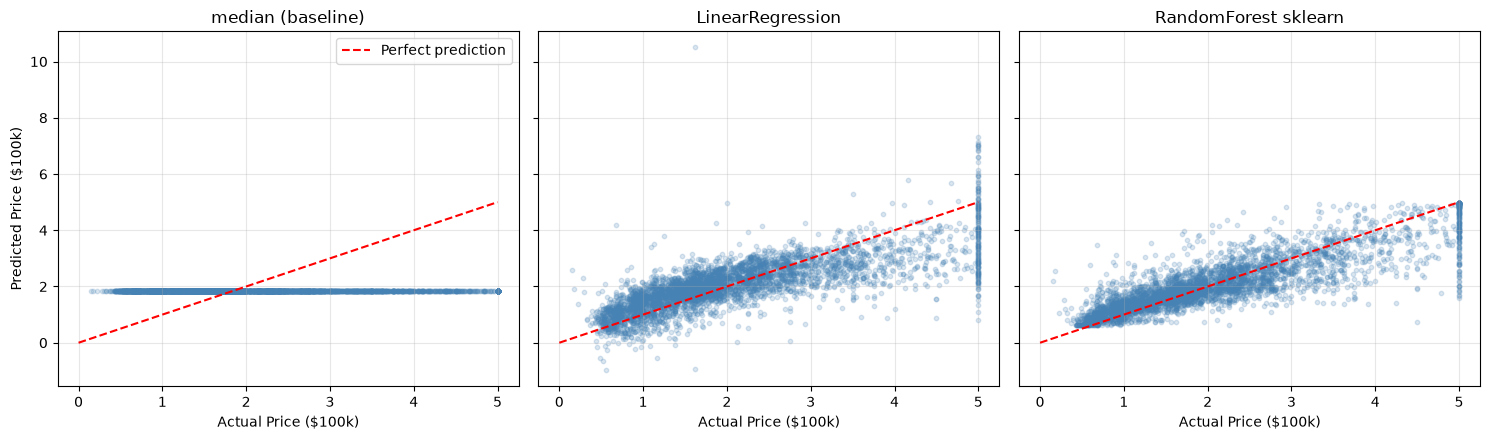

In [5]:


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (nome, m) in zip(axes, modelli.items()):
    y_pred = m.predict(X_te)
    ax.scatter(y_te, y_pred, alpha=0.2, s=10, color="steelblue")
    ax.plot([0, 5], [0, 5], "--", color="red", linewidth=1.5, label="Perfect prediction")
    ax.set_title(nome)
    ax.set_xlabel("Actual Price ($100k)")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Predicted Price ($100k)")
axes[0].legend()


plt.tight_layout()
plt.show()


### FEATURE IMPORTANCE

To look inside how `RandomForestRegressor` makes its decisions, we extract its learned `feature_importances_` (the normalized total variance reduction contributed by each variable across all 10 trees).

As expected for housing data, median income (`MedInc`) dominates the predictions, followed by geographic coordinates (`Latitude` and `Longitude`) and average occupancy (`AveOccup`). Beyond explaining what drives the model, this ranking gives us a second sanity check alongside MAE: once our custom Random Forest in `rf/` is ready, it should identify the exact same top features.


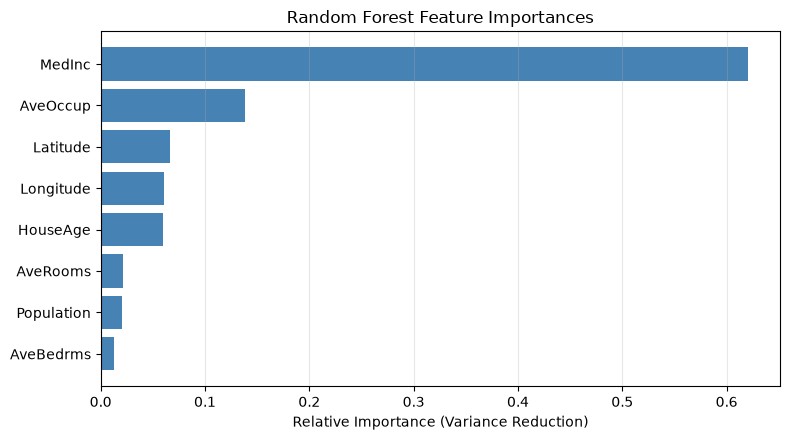

In [6]:

rf_model = modelli["RandomForest sklearn"]

feature_names = np.array(X.columns if hasattr(X, "columns") else fetch_california_housing().feature_names)
importances = rf_model.feature_importances_
idx = np.argsort(importances)

plt.figure(figsize=(8, 4.5))
plt.barh(feature_names[idx], importances[idx], color="steelblue")
plt.title("Random Forest Feature Importances")
plt.xlabel("Relative Importance (Variance Reduction)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()



### NEXT STEPS AND TARGETS

Moving from `LinearRegression` (`0.532`) to `RandomForestRegressor` (`0.413`) reduces the average error by ~$11,900, showing that spatial coordinates and the `$500k` cap need tree-based partitioning.

Checkpoints for our from-scratch implementation in `rf/`:
- Get below `0.532` MAE as a basic sanity check.
- Reach roughly `0.39–0.41` MAE (at 10 trees) to confirm parity with `scikit-learn`.

